In [28]:
import joblib
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score
)

In [11]:
# Load dataset
matches = pd.read_csv("datasets/extracted/test.csv")

# Features used for training
features = [
    "kills_per_round",
    "deaths_per_round",
    "kd_ratio",
    "headshot_rate",
    "has_kills",
    "avg_speed",
    "avg_accuracy_penalty",
    "damage_per_round", 
    "air_kill_ratio"
]

X_test = matches[features].replace([np.inf, -np.inf], np.nan)
y_test = matches["is_cheater"]

In [12]:
X_test

,kills_per_round,deaths_per_round,kd_ratio,headshot_rate,has_kills,avg_speed,avg_accuracy_penalty,damage_per_round,air_kill_ratio
0,0.153846,0.000000,2.000000,100.000000,1,36.639732,0.016531,52.615385,0.0
1,0.000000,1.000000,0.000000,NaN,0,64.470924,0.005792,3.000000,0.0
2,1.538462,0.000000,20.000000,100.000000,1,144.867320,0.011170,339.461538,0.0
3,0.307692,0.076923,4.000000,25.000000,1,97.965550,0.004076,47.461538,0.0
4,1.230769,0.076923,16.000000,100.000000,1,168.964050,0.007180,165.692308,0.0
5,1.769231,0.076923,23.000000,95.652174,1,154.444760,0.012412,321.230769,0.0
6,0.000000,1.000000,0.000000,NaN,0,177.369570,0.005119,0.846154,0.0
7,0.076923,1.000000,0.076923,0.000000,1,165.611600,0.005188,4.923077,0.0
8,0.000000,1.000000,0.000000,NaN,0,141.893480,0.005120,0.000000,0.0
9,0.000000,1.000000,0.000000,NaN,0,131.819640,0.005703,5.923077,0.0


In [13]:
y_test.sum()

np.int64(22)

In [14]:
model=joblib.load('models/v2/logistic_regression.pkl')

y_pred=model.predict(X_test)

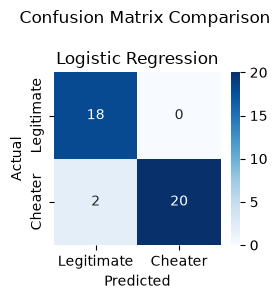

In [30]:
fig, axes = plt.subplots(1, 1, figsize=(3, 3))
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Cheater"],
    yticklabels=["Legitimate", "Cheater"],
    ax=axes
)

axes.set_title("Logistic Regression")
axes.set_xlabel("Predicted")
axes.set_ylabel("Actual")

plt.suptitle("Confusion Matrix Comparison")
plt.tight_layout()
plt.show()

In [29]:
print("Precision =",precision_score(y_test,y_pred,zero_division=0)*100,"%")
print("Recall =",recall_score(y_test,y_pred,zero_division=0)*100,"%")

Precision = 100.0 %
Recall = 90.9090909090909 %
